# Imports & Setup


In [1]:
import os
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
import copy
import hashlib
import json
import random
import pickle
import time
from pathlib import Path

import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist
from scipy.stats import sem
from scipy.special import expit
from sklearn.metrics import roc_auc_score
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
from torch_geometric.nn import GATConv, global_mean_pool

torch.set_num_threads(4)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def save_json(path, value):
    path.write_text(json.dumps(value, indent=2), encoding='utf-8')

def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def sync():
    if device.type == 'cuda':
        torch.cuda.synchronize()


# Config


In [2]:
variant = 'de_psd'
dataset_root = Path(r'C:\FACED dataset')
experiment_root = Path(r'D:\EEG Experiment Artifacts\2026-11-02\binary_de_psd')
run_dir = experiment_root / variant
run_dir.mkdir(parents=True, exist_ok=True)
run_training = True
seed = 42
epochs = 20
batch_size = 32
learning_rate = 0.001
num_classes = 2
class_names = ['Negative', 'Positive']
selected_videos = np.r_[0:12, 16:28]
feature_masks = {'de': [1]*5 + [0]*5, 'psd': [0]*5 + [1]*5, 'de_psd': [1]*10}
channels = ['Fp1','Fp2','Fz','F3','F4','F7','F8','FC1','FC2','FC5','FC6',
            'Cz','C3','C4','T7','T8','CP1','CP2','CP5','CP6','Pz','P3','P4',
            'P7','P8','PO3','PO4','Oz','O1','O2']
settings = {
    'seed': seed, 'epochs': epochs, 'batch_size': batch_size, 'learning_rate': learning_rate,
    'classes': class_names, 'channels': channels, 'selected_video_ids': (selected_videos+1).tolist(),
    'bands': [[1,4],[4,8],[8,14],[14,30],[30,47]],
    'features': 'official FACED DE and PSD files; natural log of PSD, floor 1e-20',
    'psd_definition': 'released FACED FFT/Hann features with globally normalized spectral magnitudes; not a new Welch estimate',
    'scaling': 'per channel/feature mean and std from training subjects only; floor std 1e-6',
    'input': 'ten fixed slots: five DE then five log-PSD; inactive slots masked to zero after scaling',
    'outer_folds': 10, 'inner_validation_fraction': 0.2,
    'labels': 'fixed negative/positive stimulus categories; four neutral videos excluded',
    'evaluation': 'one prediction per second, 30 seconds per trial',
    'selection': 'best validation balanced accuracy over 20 epochs; test evaluated afterwards',
    'graph': 'colin27_1020, distance < 0.15 m, 30 EEG channels',
    'cuda_scatter_may_be_nondeterministic': True
}
print('Variant:', variant, '| Device:', device)
print('Binary stimulus labels: 12 negative and 12 positive videos per subject; no neutral trials.')
print('Ten subject folds, subject-disjoint inner validation, identical model capacity and initialization.')
print('PSD means the released FACED features. Log-PSD is used; scalers are fit on training subjects only.')


Variant: de_psd | Device: cuda
Binary stimulus labels: 12 negative and 12 positive videos per subject; no neutral trials.
Ten subject folds, subject-disjoint inner validation, identical model capacity and initialization.
PSD means the released FACED features. Log-PSD is used; scalers are fit on training subjects only.


# Load & Preprocess & Split Data


In [3]:
cache_dir = experiment_root / 'cache'
cache_dir.mkdir(exist_ok=True)
feature_path = cache_dir / 'features.npy'
cache_info_path = cache_dir / 'features.json'
files = {kind: [dataset_root/'EEG_Features'/kind/f'sub{s:03d}.pkl.pkl' for s in range(123)]
         for kind in ['DE','PSD']}
input_hashes = {str(p): hashlib.sha256(p.read_bytes()).hexdigest()
                for group in files.values() for p in group}
extractor_path = dataset_root / 'EEG_Features/features_extract.py'
input_hashes[str(extractor_path)] = hashlib.sha256(extractor_path.read_bytes()).hexdigest()

if cache_info_path.exists():
    cache_info = json.loads(cache_info_path.read_text())
    assert cache_info['input_hashes'] == input_hashes
    assert cache_info['settings'] == {k: settings[k] for k in ['features','selected_video_ids','bands']}
else:
    features = np.empty((123,24,30,30,10), dtype=np.float32)
    for s in range(123):
        for kind, columns in [('DE', slice(0,5)), ('PSD', slice(5,10))]:
            with files[kind][s].open('rb') as f:
                values = np.asarray(pickle.load(f))
            assert values.shape == (28,32,30,5) and np.isfinite(values).all()
            values = values[selected_videos,:30].transpose(0,2,1,3)
            if kind == 'PSD':
                assert (values >= 0).all()
                values = np.log(np.maximum(values,1e-20))
            features[s,...,columns] = values
    features = features.reshape(2952,30,30,10)
    assert np.isfinite(features).all()
    np.save(feature_path, features)
    cache_info = {'input_hashes': input_hashes, 'shape': list(features.shape),
                  'settings': {k: settings[k] for k in ['features','selected_video_ids','bands']},
                  'cache_sha256': hashlib.sha256(feature_path.read_bytes()).hexdigest()}
    save_json(cache_info_path, cache_info)
    del features

features = np.load(feature_path, mmap_mode='r')
assert features.shape == (2952,30,30,10)
subjects = np.repeat(np.arange(123),24)
videos = np.tile(selected_videos+1,123)
video_labels = np.r_[np.zeros(12,dtype=int),np.ones(12,dtype=int)]
labels = np.tile(video_labels,123)
splits = []
for fold in range(10):
    test = np.arange(fold*12,(fold+1)*12 if fold<9 else 123)
    remaining = np.setdiff1d(np.arange(123),test)
    shuffled = np.random.default_rng(seed+fold).permutation(remaining)
    n_val = round(0.2*len(remaining))
    val, train = np.sort(shuffled[:n_val]), np.sort(shuffled[n_val:])
    assert not (set(train)&set(val) or set(train)&set(test) or set(val)&set(test))
    splits.append({'fold':fold,'train':train.tolist(),'val':val.tolist(),'test':test.tolist()})
assert sorted(s for f in splits for s in f['test']) == list(range(123))
protocol = {'settings':settings,'splits':splits,'input_hashes':input_hashes,
            'cache_sha256':cache_info['cache_sha256']}
protocol_path = experiment_root / 'protocol.json'
if protocol_path.exists():
    assert json.loads(protocol_path.read_text()) == protocol
else:
    save_json(protocol_path,protocol)
protocol_hash = hashlib.sha256(json.dumps(protocol,sort_keys=True).encode()).hexdigest()

positions = mne.channels.make_standard_montage('colin27_1020').get_positions()['ch_pos']
positions = np.stack([positions[c] for c in channels])
adjacency = cdist(positions,positions)<0.15
np.fill_diagonal(adjacency,False)
edge_index = torch.tensor(np.array(adjacency.nonzero()),dtype=torch.long)

def trial_indices(people):
    return np.flatnonzero(np.isin(subjects,people))

def fit_scaler(split):
    directory = experiment_root / 'scalers'
    directory.mkdir(exist_ok=True)
    path = directory / f"fold_{split['fold']:02d}.npz"
    if path.exists():
        saved = np.load(path)
        assert saved['protocol_hash'].item() == protocol_hash
        assert np.array_equal(saved['training_subjects'],split['train'])
        return saved['mean'],saved['std']
    train_values = np.asarray(features[trial_indices(split['train'])])
    mean = train_values.mean(axis=(0,1),dtype=np.float64)
    std = np.maximum(train_values.std(axis=(0,1),dtype=np.float64),1e-6)
    mean,std = mean.astype(np.float32),std.astype(np.float32)
    np.savez(path,mean=mean,std=std,training_subjects=split['train'],protocol_hash=protocol_hash)
    return mean,std

class Trials(Dataset):
    def __init__(self,indices,scaler):
        self.indices = np.asarray(indices)
        self.mean,self.std = scaler
    def __len__(self):
        return len(self.indices)
    def __getitem__(self,index):
        j = self.indices[index]
        values = (features[j].copy()-self.mean)/self.std
        return torch.from_numpy(values),int(labels[j])

def make_loader(indices,scaler,shuffle=False,loader_seed=42):
    return DataLoader(Trials(indices,scaler),batch_size=batch_size,shuffle=shuffle,
                      generator=torch.Generator().manual_seed(loader_seed),num_workers=0,
                      pin_memory=device.type=='cuda')

print('Trials:',len(labels),'| One-second targets:',len(labels)*30)
print('Negative/positive trial counts:',np.bincount(labels))
print('Inputs: DE slots 0-4, log-PSD slots 5-9; graph edges:',edge_index.shape[1])


Trials: 2952 | One-second targets: 88560
Negative/positive trial counts: [1476 1476]
Inputs: DE slots 0-4, log-PSD slots 5-9; graph edges: 602


# GAT + LSTM Model


In [4]:
class GATLSTM(nn.Module):
    def __init__(self,variant,init_seed):
        super().__init__()
        with torch.random.fork_rng():
            torch.manual_seed(init_seed)
            self.encoder = nn.Sequential(nn.Linear(10,32),nn.GELU(),nn.LayerNorm(32))
            self.gat1 = GATConv(32,16,heads=4,dropout=0.2)
            self.gat2 = GATConv(64,16,heads=1,dropout=0.2)
            self.lstm = nn.LSTM(16,64,batch_first=True)
            self.fc = nn.Linear(64,2)
        self.register_buffer('feature_mask',torch.tensor(feature_masks[variant],dtype=torch.float32))
        self.register_buffer('base_edges',edge_index.clone())
        self.graph_cache = {}

    def forward(self,x):
        b,t,n,d = x.shape
        h = self.encoder((x*self.feature_mask).reshape(b*t*n,d))
        count = b*t
        key = (count,x.device)
        if key not in self.graph_cache:
            offsets = torch.arange(count,device=x.device)*n
            edges = (self.base_edges[:,None,:]+offsets[None,:,None]).reshape(2,-1)
            membership = torch.arange(count,device=x.device).repeat_interleave(n)
            self.graph_cache[key] = edges,membership
        edges,membership = self.graph_cache[key]
        h = F.elu(self.gat1(h,edges))
        h = F.elu(self.gat2(h,edges))
        h = global_mean_pool(h,membership,size=count).reshape(b,t,16)
        h,_ = self.lstm(h)
        return self.fc(h)

probe_model = GATLSTM(variant,seed)
parameter_count = sum(p.numel() for p in probe_model.parameters())
print(probe_model)
print('Trainable parameters:',parameter_count,'| Active slots:',feature_masks[variant])
del probe_model


GATLSTM(
  (encoder): Sequential(
    (0): Linear(in_features=10, out_features=32, bias=True)
    (1): GELU(approximate='none')
    (2): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
  )
  (gat1): GATConv(32, 16, heads=4)
  (gat2): GATConv(64, 16, heads=1)
  (lstm): LSTM(16, 64, batch_first=True)
  (fc): Linear(in_features=64, out_features=2, bias=True)
)
Trainable parameters: 24850 | Active slots: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


# Training and Evaluation


In [5]:
def metrics_from_cm(cm):
    cm = np.asarray(cm, dtype=np.float64)
    true = cm.sum(axis=1)
    predicted = cm.sum(axis=0)
    diagonal = np.diag(cm)
    return {'accuracy': float(diagonal.sum() / cm.sum()),
            'balanced_accuracy': float(np.mean(diagonal / np.maximum(true, 1))),
            'macro_f1': float(np.mean(2 * diagonal / np.maximum(true + predicted, 1)))}

def pass_epoch(model, loader, optimizer=None, collect=False):
    training = optimizer is not None
    model.train(training)
    cm = torch.zeros(num_classes ** 2, device=device, dtype=torch.long)
    loss_sum, total = 0.0, 0
    predictions, logits_list = [], []
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            target = y[:, None].expand(-1, x.shape[1])
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(x)
            loss = F.cross_entropy(logits.reshape(-1, num_classes), target.reshape(-1))
            if not torch.isfinite(loss):
                raise FloatingPointError('Nonfinite loss')
            if training:
                loss.backward()
                norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                if not torch.isfinite(norm):
                    raise FloatingPointError('Nonfinite gradient')
                optimizer.step()
            predicted = logits.argmax(dim=-1)
            cm += torch.bincount((target * num_classes + predicted).reshape(-1), minlength=num_classes ** 2)
            total += target.numel()
            loss_sum += loss.item() * target.numel()
            if collect:
                predictions.append(predicted.cpu().numpy())
                logits_list.append(logits.cpu().numpy())
    matrix = cm.reshape(num_classes, num_classes).cpu().numpy()
    result = {'loss': loss_sum / total, **metrics_from_cm(matrix)}
    return result, matrix, (np.concatenate(predictions) if collect else None), (np.concatenate(logits_list) if collect else None)

def run_fold(split):
    fold = split['fold']
    folder = run_dir / f'fold_{fold:02d}'
    folder.mkdir(exist_ok=True)
    scaler = fit_scaler(split)
    manifest = {'protocol_hash': protocol_hash, 'variant': variant, 'fold': fold,
                'parameters': parameter_count, 'settings': settings,
                'torch': torch.__version__, 'mne': mne.__version__,
                'gpu': torch.cuda.get_device_name(0) if device.type == 'cuda' else None}
    config_path = folder / 'config.json'
    if config_path.exists():
        existing = json.loads(config_path.read_text())
        for key in ['protocol_hash', 'variant', 'fold', 'parameters', 'settings']:
            assert existing[key] == manifest[key], f'Run configuration changed: {key}'
    else:
        save_json(config_path, manifest)
    if (folder / 'metrics.json').exists():
        assert (folder / 'predictions.npz').exists() and (folder / 'best_model.pt').exists()
        print('Restored completed fold', fold, flush=True)
        return json.loads((folder / 'metrics.json').read_text())

    train_idx, val_idx, test_idx = [trial_indices(split[k]) for k in ['train', 'val', 'test']]
    np.savez(folder / 'split_indices.npz', train=train_idx, val=val_idx, test=test_idx)
    seed_all(seed + fold)
    train_loader = make_loader(train_idx, scaler, True, seed + fold)
    val_loader = make_loader(val_idx, scaler)
    model = GATLSTM(variant, seed + fold).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    history, best_score = [], -1.0
    started = time.perf_counter()
    for epoch in range(1, epochs + 1):
        epoch_start = time.perf_counter()
        train_metrics, _, _, _ = pass_epoch(model, train_loader, optimizer)
        val_metrics, _, _, _ = pass_epoch(model, val_loader)
        row = {'epoch': epoch, 'seconds': time.perf_counter() - epoch_start,
               **{'train_' + k: v for k, v in train_metrics.items()},
               **{'val_' + k: v for k, v in val_metrics.items()}}
        history.append(row)
        pd.DataFrame(history).to_csv(folder / 'history.csv', index=False)
        if val_metrics['balanced_accuracy'] > best_score:
            best_score = val_metrics['balanced_accuracy']
            torch.save({'state_dict': model.state_dict(), 'epoch': epoch,
                        'validation': val_metrics, 'config': manifest}, folder / 'best_model.pt')
        print(f"{variant} fold {fold} epoch {epoch}/{epochs}: train={train_metrics['accuracy']:.4f}, val BAcc={val_metrics['balanced_accuracy']:.4f}", flush=True)

    checkpoint = torch.load(folder / 'best_model.pt', map_location=device, weights_only=False)
    model.load_state_dict(checkpoint['state_dict'])
    # The outer test set is first evaluated after selecting the validation checkpoint.
    test_metrics, matrix, predicted, logits = pass_epoch(model, make_loader(test_idx, scaler), collect=True)
    target = np.repeat(labels[test_idx, None], 30, axis=1)
    test_metrics['roc_auc'] = float(roc_auc_score(target.ravel(), expit(logits[...,1]-logits[...,0]).ravel()))
    np.savez_compressed(folder / 'predictions.npz', predictions=predicted, logits=logits,
                        labels=target, subjects=subjects[test_idx], videos=videos[test_idx])
    np.savetxt(folder / 'confusion_matrix.csv', matrix, fmt='%d', delimiter=',')
    result = {'fold': fold, 'test_subjects': split['test'], 'best_epoch': checkpoint['epoch'],
              'validation': checkpoint['validation'], 'test': test_metrics,
              'seconds': time.perf_counter() - started}
    save_json(folder / 'metrics.json', result)
    print('FOLD COMPLETE', json.dumps(result), flush=True)
    del model, optimizer
    if device.type == 'cuda':
        torch.cuda.empty_cache()
    return result

def summarize():
    predictions = np.full((123, 24, 30), -1, dtype=np.int64)
    fold_results = []
    positive_probability = np.empty((123,24,30),dtype=np.float32)
    for split in splits:
        folder = run_dir / f"fold_{split['fold']:02d}"
        result = json.loads((folder / 'metrics.json').read_text())
        fold_results.append(result)
        saved = np.load(folder / 'predictions.npz')
        for sub in split['test']:
            mask = saved['subjects'] == sub
            assert np.array_equal(saved['videos'][mask], selected_videos + 1)
            assert mask.sum() == 24
            predictions[sub] = saved['predictions'][mask]
            positive_probability[sub] = expit(saved['logits'][mask,...,1]-saved['logits'][mask,...,0])
    target = np.tile(np.repeat(video_labels[:, None], 30, axis=1)[None], (123, 1, 1))
    assert (predictions >= 0).all()
    subject_metrics = []
    cm = np.zeros((num_classes, num_classes), dtype=np.int64)
    for sub in range(123):
        sub_cm = np.bincount((target[sub] * num_classes + predictions[sub]).reshape(-1), minlength=num_classes ** 2).reshape(num_classes, num_classes)
        cm += sub_cm
        subject_metrics.append({'subject': sub, **metrics_from_cm(sub_cm), 'roc_auc':float(roc_auc_score(target[sub].ravel(),positive_probability[sub].ravel()))})
    np.savez_compressed(run_dir / 'out_of_fold_predictions.npz', predictions=predictions, labels=target, positive_probability=positive_probability)
    pd.DataFrame(subject_metrics).to_csv(run_dir / 'subject_metrics.csv', index=False)
    np.savetxt(run_dir / 'confusion_matrix.csv', cm, fmt='%d', delimiter=',')
    scores = np.array([s['accuracy'] for s in subject_metrics])
    result = {'variant': variant, 'protocol_hash': protocol_hash, 'parameters': parameter_count,
              **metrics_from_cm(cm), 'roc_auc':float(roc_auc_score(target.ravel(),positive_probability.ravel())), 'subject_accuracy_sem': float(sem(scores)),
              'subjects': 123, 'one_second_predictions': int(target.size),
              'folds': fold_results, 'total_fold_seconds': sum(f['seconds'] for f in fold_results)}
    save_json(run_dir / 'summary.json', result)
    return result


# Check Model & Estimate Runtime


In [6]:
profile_path = run_dir / 'profile.json'
if profile_path.exists():
    profile = json.loads(profile_path.read_text())
    assert profile['protocol_hash'] == protocol_hash
else:
    train_idx = trial_indices(splits[0]['train'])
    scaler = fit_scaler(splits[0])
    seed_all(seed)
    model = GATLSTM(variant,seed).to(device)
    model.eval()
    sample = torch.from_numpy((features[train_idx[:2]].copy()-scaler[0])/scaler[1]).to(device)
    with torch.no_grad():
        together = model(sample)
        separate = torch.cat([model(sample[i:i+1]) for i in range(2)])
    batch_error = float((together-separate).abs().max())
    assert together.shape == (2,30,2)
    assert torch.allclose(together,separate,atol=2e-5,rtol=1e-4)
    inactive = model.feature_mask == 0
    if inactive.any():
        perturbed = sample.clone()
        perturbed[...,inactive] += torch.randn_like(perturbed[...,inactive])*100
        with torch.no_grad():
            assert torch.allclose(together,model(perturbed),atol=2e-5,rtol=1e-4)
    for other_variant in feature_masks:
        other = GATLSTM(other_variant,seed)
        assert all(torch.equal(value.cpu(),dict(other.named_parameters())[name])
                   for name,value in model.named_parameters())
        del other
    optimizer = torch.optim.Adam(model.parameters(),lr=learning_rate)
    times = []
    for x,y in make_loader(train_idx[:batch_size*4],scaler):
        model.train()
        sync()
        start = time.perf_counter()
        x,y = x.to(device),y.to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        loss = F.cross_entropy(logits.reshape(-1,2),y[:,None].expand(-1,30).reshape(-1))
        loss.backward()
        assert torch.isfinite(loss)
        gradient = model.encoder[0].weight.grad
        assert gradient[:,~inactive].norm().item() > 0
        if inactive.any():
            assert gradient[:,inactive].abs().max().item() == 0
        optimizer.step()
        sync()
        times.append(time.perf_counter()-start)
    model.eval()
    sync()
    start = time.perf_counter()
    with torch.no_grad():
        model(x)
    sync()
    eval_seconds = time.perf_counter()-start
    train_seconds = float(np.median(times[1:]))
    estimate = 0
    for split in splits:
        estimate += epochs*(np.ceil(len(trial_indices(split['train']))/batch_size)*train_seconds
                           +np.ceil(len(trial_indices(split['val']))/batch_size)*eval_seconds)
        estimate += np.ceil(len(trial_indices(split['test']))/batch_size)*eval_seconds
    profile = {'protocol_hash':protocol_hash,'train_batch_seconds':train_seconds,
               'eval_batch_seconds':eval_seconds,'estimated_seconds':float(estimate),
               'batch_equivalence_max_error':batch_error,'finite_gradient_check':True,
               'all_parameter_initializations_equal':True,'inactive_features_have_no_effect':True,
               'parameters':parameter_count,
               'peak_gpu_mb':torch.cuda.max_memory_allocated()/2**20 if device.type=='cuda' else None}
    save_json(profile_path,profile)
    del model,optimizer,sample,x,y,logits
    if device.type=='cuda':
        torch.cuda.empty_cache()
print(json.dumps(profile,indent=2))
print('Estimated ten-fold minutes:',round(profile['estimated_seconds']/60,1))


{
  "protocol_hash": "f141d1961368b30c2d47c45d1ccb3292d52ec2a635c5a24dadc8b136f77875a0",
  "train_batch_seconds": 0.028851200000644894,
  "eval_batch_seconds": 0.011074799998823437,
  "estimated_seconds": 424.13630840450605,
  "batch_equivalence_max_error": 2.9802322387695312e-08,
  "finite_gradient_check": true,
  "all_parameter_initializations_equal": true,
  "inactive_features_have_no_effect": true,
  "parameters": 24850,
  "peak_gpu_mb": 746.22119140625
}
Estimated ten-fold minutes: 7.1


# Run Training


In [7]:
if run_training:
    for split in splits:
        run_fold(split)
    results = summarize()
else:
    results = json.loads((run_dir / 'summary.json').read_text())
print('Completed:', variant)


de_psd fold 0 epoch 1/20: train=0.5099, val BAcc=0.5331
de_psd fold 0 epoch 2/20: train=0.5286, val BAcc=0.5411
de_psd fold 0 epoch 3/20: train=0.5377, val BAcc=0.5387
de_psd fold 0 epoch 4/20: train=0.5336, val BAcc=0.5512
de_psd fold 0 epoch 5/20: train=0.5402, val BAcc=0.5444
de_psd fold 0 epoch 6/20: train=0.5381, val BAcc=0.5441
de_psd fold 0 epoch 7/20: train=0.5344, val BAcc=0.5446
de_psd fold 0 epoch 8/20: train=0.5399, val BAcc=0.5415
de_psd fold 0 epoch 9/20: train=0.5388, val BAcc=0.5444
de_psd fold 0 epoch 10/20: train=0.5450, val BAcc=0.5443
de_psd fold 0 epoch 11/20: train=0.5464, val BAcc=0.5497
de_psd fold 0 epoch 12/20: train=0.5472, val BAcc=0.5345
de_psd fold 0 epoch 13/20: train=0.5527, val BAcc=0.5414
de_psd fold 0 epoch 14/20: train=0.5447, val BAcc=0.5188
de_psd fold 0 epoch 15/20: train=0.5540, val BAcc=0.5511
de_psd fold 0 epoch 16/20: train=0.5522, val BAcc=0.5511
de_psd fold 0 epoch 17/20: train=0.5568, val BAcc=0.5472
de_psd fold 0 epoch 18/20: train=0.5597,

# Test Results


In [8]:
oof = np.load(run_dir/'out_of_fold_predictions.npz')
predictions,targets = oof['predictions'],oof['labels']
subject_results = pd.read_csv(run_dir/'subject_metrics.csv')
assert predictions.shape == targets.shape == (123,24,30)
assert np.isclose((predictions==targets).mean(),results['accuracy'])
print(pd.Series({k:results[k]*100 for k in
    ['accuracy','subject_accuracy_sem','balanced_accuracy','macro_f1','roc_auc']}).round(2).to_string())
print('Subjects:',results['subjects'],'| One-second predictions:',results['one_second_predictions'])
print('Parameters:',results['parameters'])
print('Balanced binary classes; constant-class accuracy baseline is 50%.')
print('Single base seed, 20 epochs per fold; no threshold tuning on test subjects.')


accuracy                53.54
subject_accuracy_sem     0.59
balanced_accuracy       53.54
macro_f1                53.54
roc_auc                 54.63
Subjects: 123 | One-second predictions: 88560
Parameters: 24850
Balanced binary classes; constant-class accuracy baseline is 50%.
Single base seed, 20 epochs per fold; no threshold tuning on test subjects.


# Plot Results


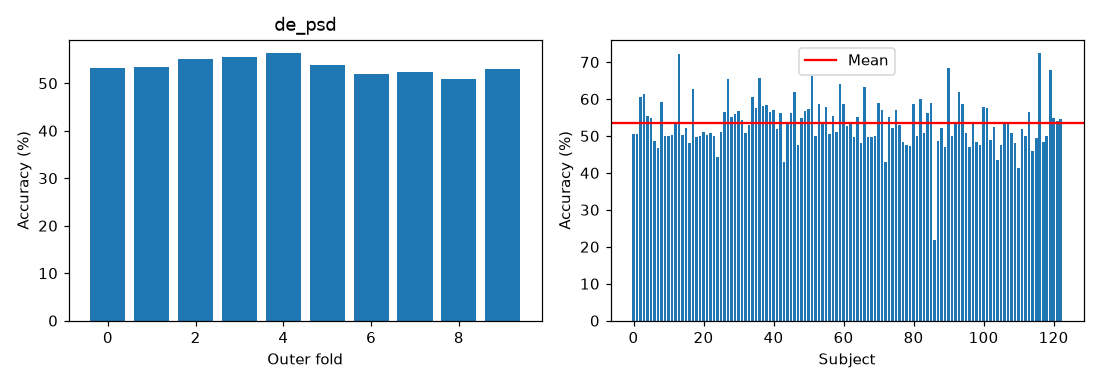

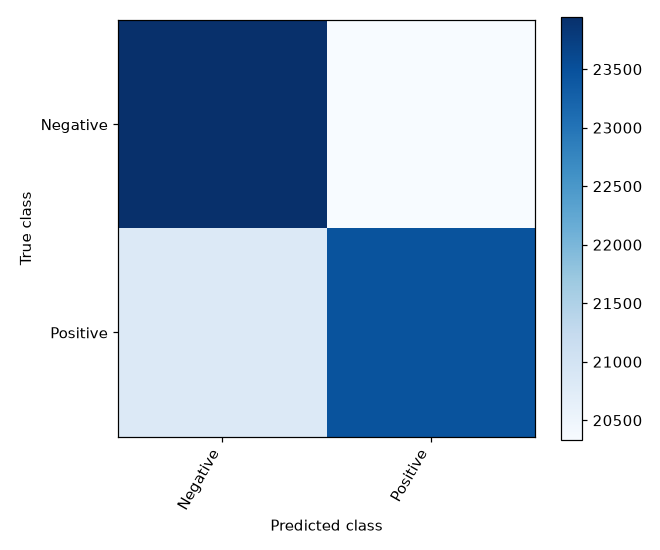

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
fold_scores = [f['test']['accuracy'] * 100 for f in results['folds']]
axes[0].bar(np.arange(10), fold_scores)
axes[0].set(xlabel='Outer fold', ylabel='Accuracy (%)', title=variant)
axes[1].bar(subject_results['subject'], subject_results['accuracy'] * 100)
axes[1].axhline(results['accuracy'] * 100, color='red', label='Mean')
axes[1].set(xlabel='Subject', ylabel='Accuracy (%)')
axes[1].legend()
fig.tight_layout()
plt.show()

matrix = np.bincount((targets * num_classes + predictions).ravel(), minlength=num_classes ** 2).reshape(num_classes, num_classes)
fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(matrix, cmap='Blues')
ax.set(xticks=np.arange(num_classes), yticks=np.arange(num_classes), xlabel='Predicted class', ylabel='True class')
ax.set_xticklabels(class_names, rotation=60, ha='right')
ax.set_yticklabels(class_names)
fig.colorbar(image, ax=ax)
fig.tight_layout()
plt.show()
